## Agonist-induced G protein activation model

We developed an integrative meta-model that recapitulates MOR ligand–dependent G protein activation and dissociation kinetics.
the model integrates simulations and experiments for the nucleotide-free and GTP bound systems.

- Ligand-dependent GTP loading onto receptor-bound G protein is modeled using the dynamics of the nucleotide-free G protein:
$$k^{\rm (eff)}_{\rm on}([N]) = k_{co}^{\varnothing,l} \frac{k_{\rm on}[N]}{k_{\rm on}[N] + k_{oc}^{\varnothing,l}}$$
The protein rates are obtained from the integrative smFRET- kinetic scheme from Deutsch & co.; with $k_{\rm on}$ estimated from published data.

- The subsequent dynamics of the GTP-bound complex are described using a simplified state network informed by molecular simulations; modeled states include a "threshold" partially dissociated state $N$ coupled to a fully dissociated state $U$; while the B states possibly include a kinetic trap to a non-productive state $T$:
$$B \;\underset{k_{NB}}{\overset{k_{BN}}{\rightleftharpoons}}\; N \;\xrightarrow{k_U}\; U$$
and this module is integrated with the Robertson/Blanchard TIRF dissociation kinetics.

Across ligands, the model reproduces the two characteristic timescales reported in TIRF experiments:
- The fast, ligand-dependent component is explained by the GTP-loading step and is quantitatively accounted for by the Deutsch smFRET kinetics; partial agonists keep the protein more closed and therefore reduce GTP loading.
- The slower component reflects the occupancy the a late near-dissociated intermediate $N$ along the disengagement pathway.
longer slow-timescales for partial ligands are explained by increased population of the non-productive state $T$ that transiently sequesters population, thereby modulating the long-timescale behavior.

## Notes
### Results below assume bi-exponential and infer the times
The minimal model below fits a bi-exponential function on the TIRF data; with a prior on the population $p_\ell(N)$.
With data from our MSM we should use the right un-projected functional form.


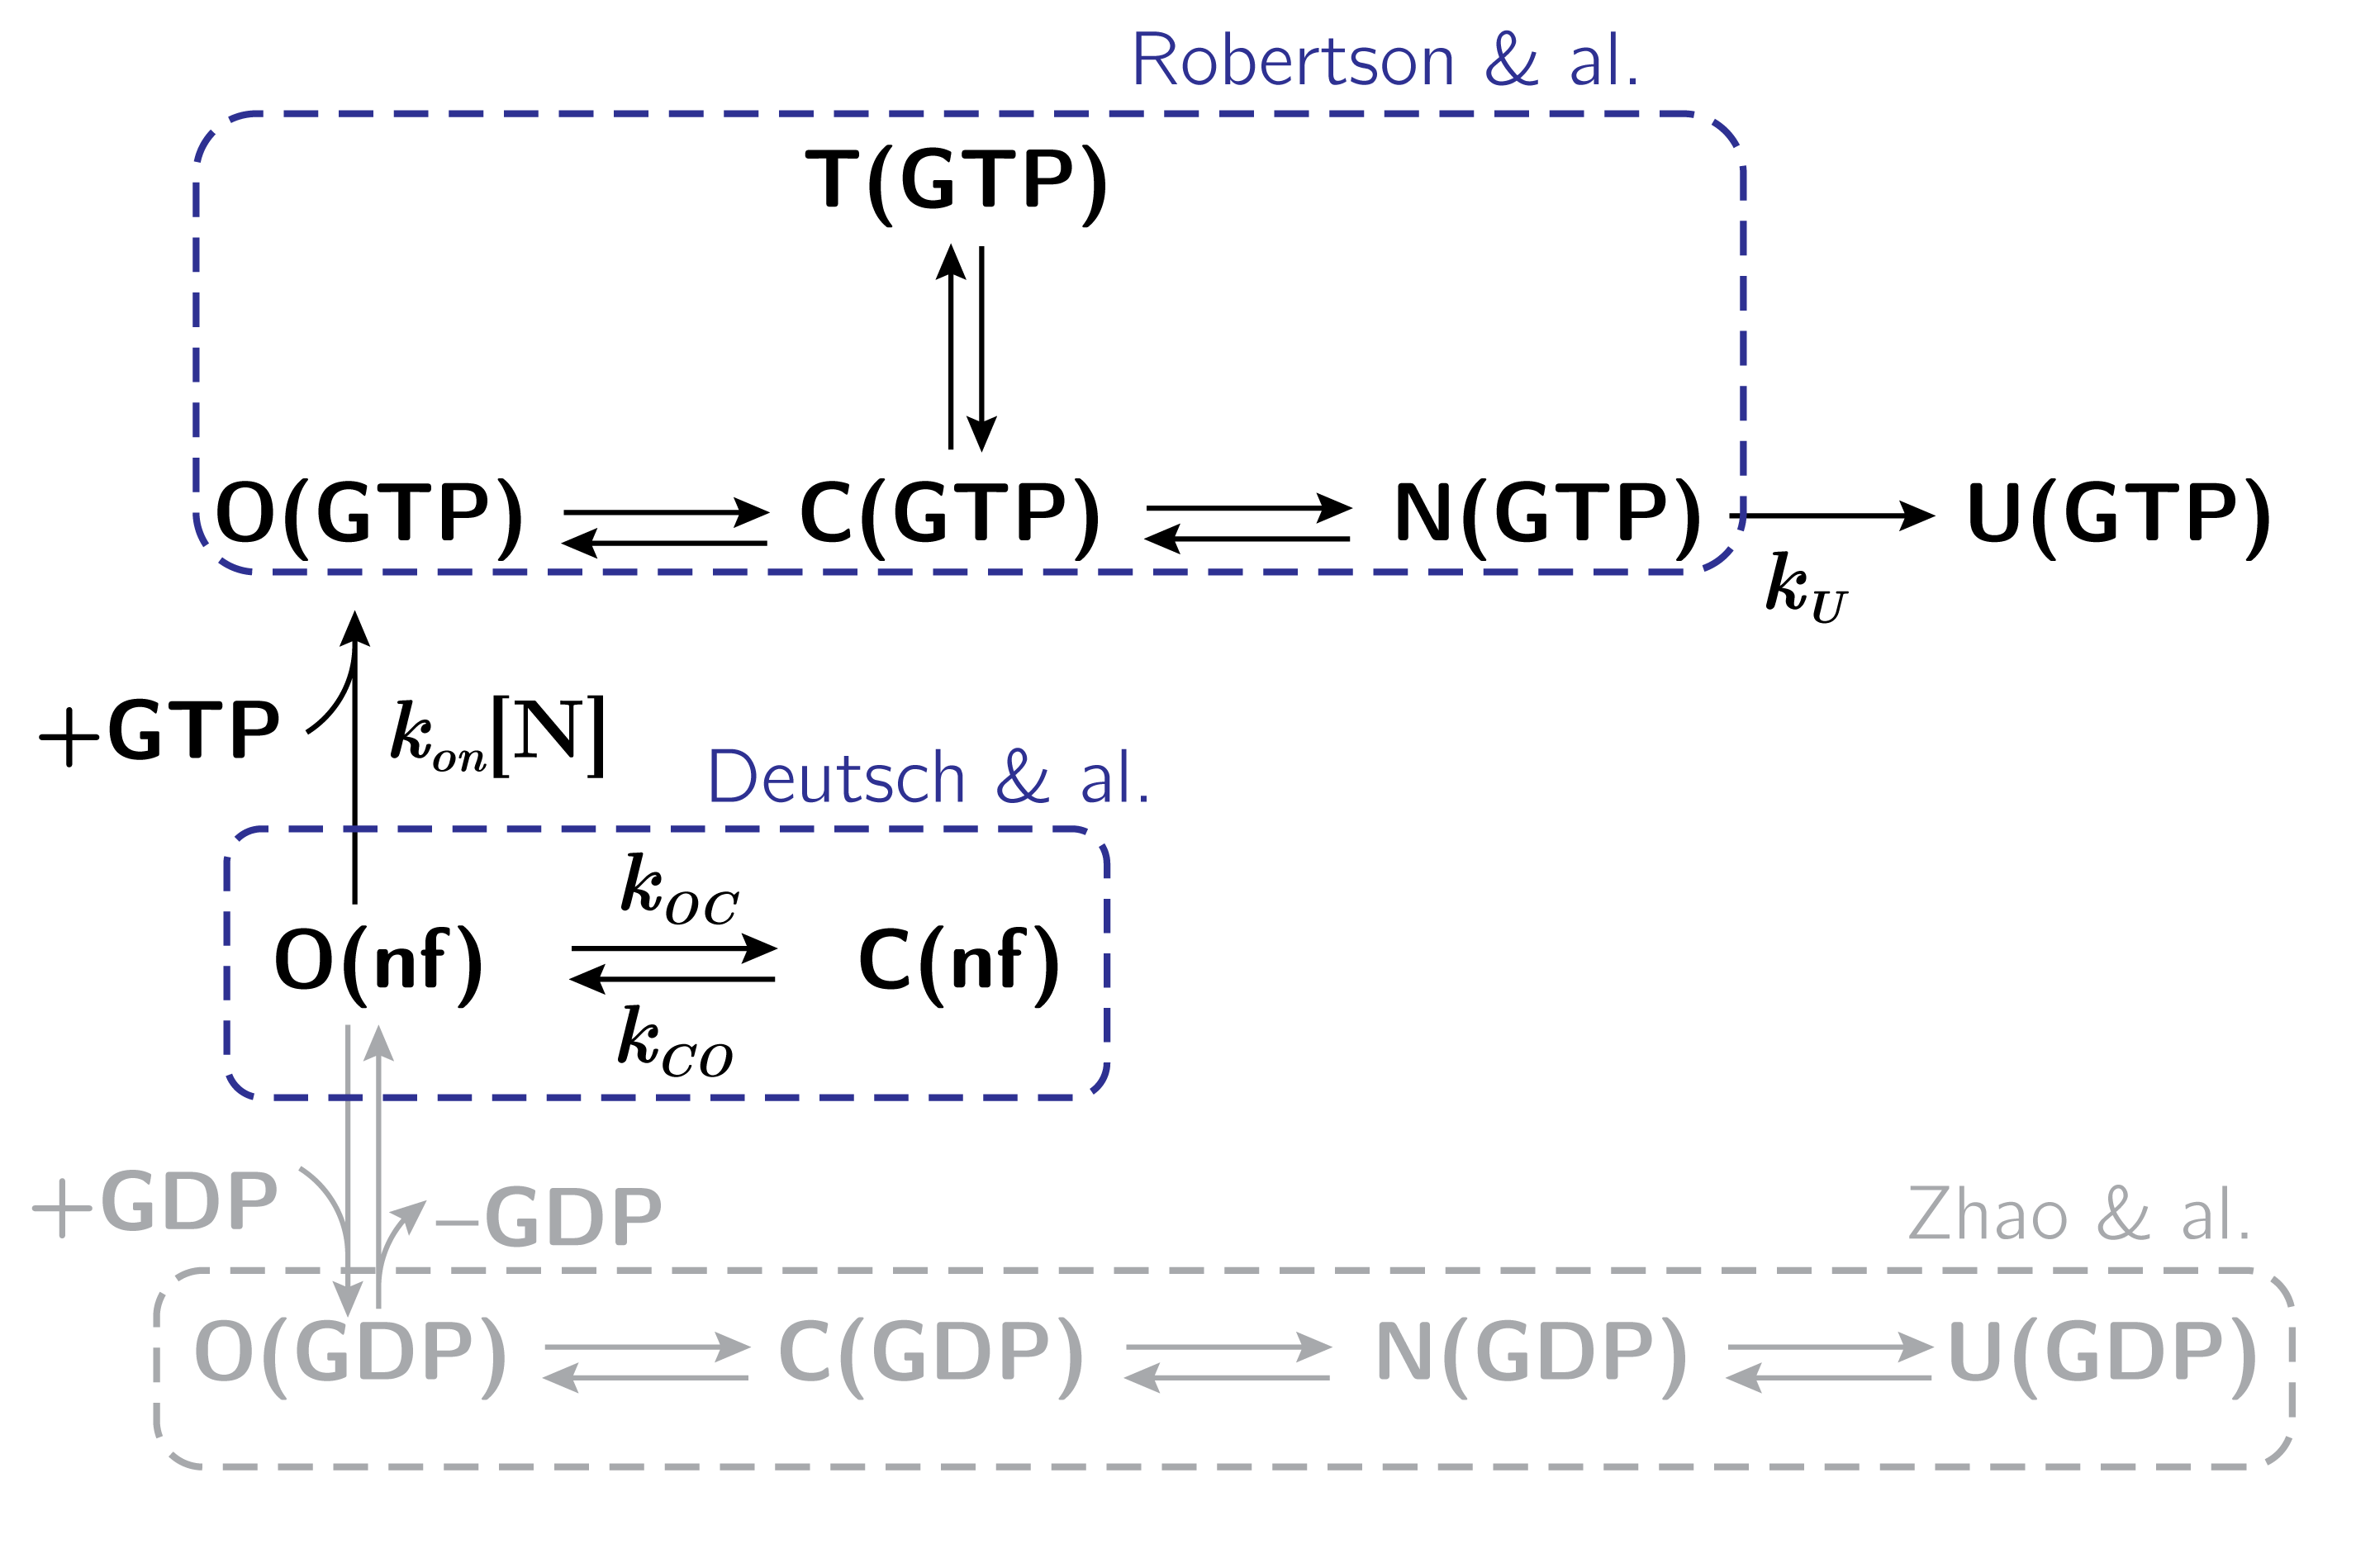

### note on GTP rate
[Ravi's paper](https://www.sciencedirect.com/science/article/pii/S0021925819393202) reports a average effective $k_{\rm on}^{\rm (eff)}=0.1~{\rm min}^{-1}$ at $[GTP]=1~\mu M$. The effective GTP binding rate, assuming that the nucleotide can bind only to the open state is
$$
k^{\rm (eff)}_{\rm on}([N]) = k_{co}^{\varnothing,l} \frac{k_{\rm on}[N]}{k_{\rm on}[N] + k_{oc}^{\varnothing,l}}
$$
Here, we can used the gating kinetics from [Kobilka's sm-FRET data](https://pmc.ncbi.nlm.nih.gov/articles/PMC12236782/)
for the APO 1.2 sec (closed) and 2.8 sec (open), though this is with the receptor.
$k_{co}\sim \ln 2/\tau_c \approx 34~{\rm min}^{-1}$
$k_{oc}\sim \ln 2/\tau_o \approx 14~{\rm min}^{-1}$
the nucleotide-free protein has relatively fast dynamics.

For $1 \mu M$ GTP (used in Robertson), we are in a regime where $k_{\rm on} [N]  =  0.04~{\rm min}^{-1} \ll k_{oc}$



In [ ]:
import numpy as np
import pandas as pd
import pymc as pm

In [ ]:
import numpy as np
import pymc as pm

# --- ragged inputs for dissociation from Robertson ---
import numpy as np

# Ligand 0: LFT
t_LFT = np.array([
    1.2811387900355804,
    2.8825622775800674,
    5.444839857651239,
    13.45195729537366,
    29.1459074733096,
    49.3238434163701,
    86.79715302491104,
    117.54448398576511,
    152.77580071174376,
    184.16370106761565
], dtype=float)

y_LFT = np.array([
    0.9930067036332038,
    0.8953115948026154,
    0.8301622113713483,
    0.7393610858230573,
    0.6484606471902674,
    0.5714557642969461,
    0.4942274269635025,
    0.45662087229992565,
    0.4212819663990731,
    0.3976206240172142
], dtype=float)


# Ligand 1: MP
t_MP = np.array([
    0.9608540925266951,
    6.085409252669034,
    17.615658362989322,
    35.231316725978644,
    60.53380782918148,
    90.64056939501779,
    114.66192170818505,
    137.4021352313167,
    159.8220640569395,
    181.28113879003556,
    192.49110320284694
], dtype=float)

y_MP = np.array([
    0.993035669949516,
    0.9045725399321362,
    0.8416328726309692,
    0.7832657452619384,
    0.7247993048084087,
    0.6778987006538113,
    0.6613092774973104,
    0.6563643134983035,
    0.6467723247537863,
    0.6418439129355293,
    0.6579781511214103
], dtype=float)




In [ ]:

# Final lists for the model
t_list = [t_LFT, t_MP]
y_list = [y_LFT, y_MP]


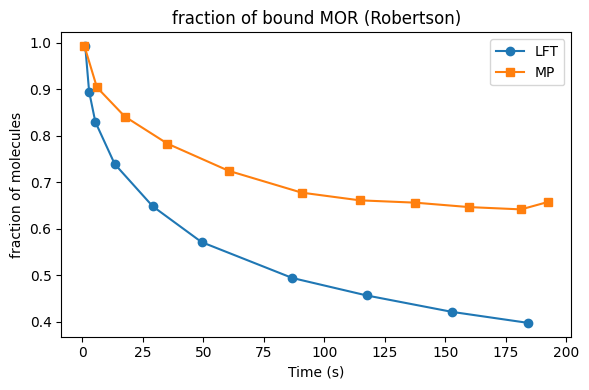

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(6,4))

plt.plot(t_LFT, y_LFT, 'o-', label='LFT')
plt.plot(t_MP, y_MP, 's-', label='MP')


plt.xlabel("Time (s)")
plt.ylabel("fraction of molecules")
plt.title("fraction of bound MOR (Robertson)")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
L = len(t_list)
n_per = np.array([len(x) for x in t_list], dtype=int)
t_all = np.concatenate(t_list).astype(float)
y_all = np.concatenate(y_list).astype(float)
lig_id = np.concatenate([np.full(n, i, dtype=int) for i, n in enumerate(n_per)])


In [ ]:

with pm.Model() as m:
    # Shared intrinsic dissociation from N
    # pick center to match timescale??
    log_kU = pm.Normal("log_kU", mu=np.log(1), sigma=2.5)
    kU = pm.Deterministic("kU", pm.math.exp(log_kU))

    # Ligand-specific fN (logit-normal hierarchy)
    # logit scale
    #mu_f = pm.Normal("mu_f", mu=0.0, sigma=1.5)
    #sig_f = pm.HalfNormal("sig_f", sigma=1.0)
    #z_f = pm.Normal("z_f", mu=mu_f, sigma=sig_f, shape=L)


    z_f = pm.Normal("z_f", mu=[-3.,-5.], sigma=0.01)
    fN = pm.Deterministic("fN", pm.math.sigmoid(z_f))



    # kleak is the rate from N
    kleak = pm.Deterministic("kleak", kU * fN)

    # -------------------------
    # Ligand-specific kb
    N_lig = np.array([1, 1], dtype=float)  # length L

    ## priors on Deutsch open/close
    log_kco = pm.Normal("log_kco", mu=np.log(0.03), sigma=0.7, shape=L)
    log_koc = pm.Normal("log_koc", mu=np.log(0.30), sigma=0.7, shape=L)
    log_kon = pm.Normal("log_kon", mu=np.log(1000*0.04/60), sigma=0.001)  # shared across ligands, from Ravi/Dror

    kco = pm.Deterministic("kco", pm.math.exp(log_kco))  # (L,)
    koc = pm.Deterministic("koc", pm.math.exp(log_koc))  # (L,)
    kon = pm.Deterministic("kon", pm.math.exp(log_kon))  # scalar
    kb_lig = pm.Deterministic( "kb_lig", kco * (kon * N_lig) / (kon * N_lig + koc))


    ## likelihood from Deutsch: assume mean and sd
    #tau_co = pm.Deterministic("tau_co", 1.0 / kco)  # mean closed dwell
    #tau_oc = pm.Deterministic("tau_oc", 1.0 / koc)  # mean open dwell
    #tau_co_obs = np.array([1.3,2.5], dtype=float)  # = 1/kco observed
    #tau_oc_obs = np.array([1.6,0.9], dtype=float)  # = 1/koc observed
    ## measurement error on log-scale (can be fixed from SD, or estimated)
    #sig_log_tau_co = pm.HalfNormal("sig_log_tau_co", sigma=0.2)
    #sig_log_tau_oc = pm.HalfNormal("sig_log_tau_oc", sigma=0.2)
    #pm.LogNormal("tau_co_obs", mu=pm.math.log(tau_co), sigma=sig_log_tau_co, observed=tau_co_obs)
    #pm.LogNormal("tau_oc_obs", mu=pm.math.log(tau_oc), sigma=sig_log_tau_oc, observed=tau_oc_obs)

    ## assume Gamma and ! one transition per trace
    N_co = np.array([200, 200], dtype=int)
    N_oc = np.array([200, 200], dtype=int)
    # mean dwell times implied by rates
    tau_co = pm.Deterministic("tau_co", 1.0 / kco)  # mean closed dwell
    tau_oc = pm.Deterministic("tau_oc", 1.0 / koc)  # mean open dwell
    tau_co_obs = np.array([1.3, 2.5], dtype=float)  # observed sample mean closed dwell
    tau_oc_obs = np.array([1.6, 0.9], dtype=float)  # observed sample mean open dwell

    ## likelihoo for Deutsch
    pm.Gamma("tau_co_mean_obs", alpha=N_co, beta=N_co / tau_co, observed=tau_co_obs)
    pm.Gamma("tau_oc_mean_obs", alpha=N_oc, beta=N_oc / tau_oc, observed=tau_oc_obs)

    # Compute U(t) for each observation i
    kb_i = kb_lig[lig_id]
    kleak_i = kleak[lig_id]

    # direct sequential model does not work because the signs are opposite.
    #eps = 1e-9
    #denom = kleak_i - kb_i
    #denom = pm.math.where(pm.math.abs(denom) < eps, eps, denom)
    ###U = 1.0 - (kleak_i * pm.math.exp(-kb_i * t_all) - kb_i * pm.math.exp(-kleak_i * t_all)) / denom

    # Predicted mean tirf (Robertson)

    #
    if True:
      Sinf = pm.Beta("Sinf", alpha=1.5, beta=1.5, shape=L)  # prior favors small plateau; tune as needed
      w = pm.Beta("w", alpha=2.0, beta=2.0, shape=L)
      S_decay = w[lig_id] * pm.math.exp(-kb_i * t_all) + (1.0 - w[lig_id]) * pm.math.exp(-kleak_i * t_all)
      S = pm.Deterministic("S", Sinf[lig_id] + (1.0 - Sinf[lig_id]) * S_decay)
      U = pm.Deterministic("U", 1.0 - S)
      y_hat = pm.Deterministic("y_hat", S)
    else:
      # baseline needs to be justified
      ## mixed model needs to be better justified
      w = pm.Beta("w", alpha=2.0, beta=2.0, shape=L)
      S = (w[lig_id] * pm.math.exp(-kb_i * t_all) + (1.0 - w[lig_id]) * pm.math.exp(-kleak_i * t_all))
      U = pm.Deterministic("U", 1.0 - S)
      A = pm.HalfNormal("A", sigma=1.0, shape=L)
      y_inf = pm.Normal("y_inf", mu=0.0, sigma=0.3, shape=L)
      y_hat = pm.Deterministic("y_hat", y_inf[lig_id] + A[lig_id]*S)

    # Likelihood for TIRF
    # Normal
    # pm.Normal("y_obs", mu=y_hat, sigma=sigma[lig_id], observed=y_all)

    # Student, Degrees of freedom (nu > 1)
    sigma = pm.HalfNormal("sigma", sigma=0.05, shape=L)
    nu_minus1 = pm.Exponential("nu_minus1", 1.0)
    nu = pm.Deterministic("nu", nu_minus1 + 1.0)
    pm.StudentT("y_obs", nu=nu, mu=y_hat, sigma=sigma[lig_id], observed=y_all)


    tau1 = pm.Deterministic("tau1",1/kb_lig)
    tau2 = pm.Deterministic("tau2",1/kleak)

    idata = pm.sample(target_accept=0.9,
                      chains=4
                      )

Output()

In [ ]:
import arviz as az
summ = az.summary(idata,var_names=["tau1","tau2","fN","tau_co","tau_oc","kon","kco","koc","kU","Sinf"])
#summ = add_KL_to_summary(summ, trace, prior_info)
summ

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
tau1[0],2.685,0.218,2.299,3.091,0.003,0.004,4273.0,2723.0,1.0
tau1[1],7.079,0.626,5.991,8.282,0.009,0.011,5112.0,2856.0,1.0
tau2[0],48.283,9.520,30.699,67.129,0.253,0.284,1490.0,945.0,1.0
tau2[1],342.135,67.575,223.814,481.838,1.794,1.990,1495.0,973.0,1.0
fN[0],0.047,0.000,0.047,0.048,0.000,0.000,5339.0,3292.0,1.0
fN[1],0.007,0.000,0.007,0.007,0.000,0.000,4741.0,2995.0,1.0
tau_co[0],1.384,0.101,1.204,1.579,0.002,0.002,4476.0,2325.0,1.0
tau_co[1],2.649,0.198,2.266,3.008,0.003,0.003,4770.0,2528.0,1.0
tau_oc[0],1.603,0.114,1.388,1.814,0.002,0.002,4729.0,2818.0,1.0
tau_oc[1],0.902,0.064,0.787,1.021,0.001,0.001,4861.0,2765.0,1.0


In [ ]:
kUpost=idata.posterior["kU"].values.reshape(-1)
np.mean(1/kUpost) #sec


np.float64(2.289856988918459)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

if False:
      lig_names = ["LFT", "MP"]  # adjust if needed

      def flat(var):
          x = idata.posterior[var].values  # (chain, draw, L)
          return x.reshape(-1, x.shape[-1])

      yhat_s = flat("y_hat")  # (S, N)

      yhat_mean = yhat_s.mean(axis=0)
      yhat_lo   = np.quantile(yhat_s, 0.025, axis=0)
      yhat_hi   = np.quantile(yhat_s, 0.975, axis=0)

      fig, axes = plt.subplots(1, L, figsize=(6*L, 4), sharey=True)
      if L == 1:
          axes = [axes]

      start = 0
      for ell in range(L):
          end = start + n_per[ell]

          t_ell = t_all[start:end]
          y_ell = y_all[start:end]

          m_ell = yhat_mean[start:end]
          lo_ell = yhat_lo[start:end]
          hi_ell = yhat_hi[start:end]

          ax = axes[ell]
          ax.plot(t_ell, y_ell, 'o', label="experiment")
          ax.plot(t_ell, m_ell, '-', label="posterior mean (y_hat)")
          ax.fill_between(t_ell, lo_ell, hi_ell, alpha=0.3, label="95% CI")

          ax.set_xlabel("Time (s)")
          ax.set_ylabel("FRET")
          ax.set_title(lig_names[ell] if ell < len(lig_names) else f"Ligand {ell}")
          ax.legend(loc="best")

          start = end

      plt.tight_layout()
      plt.show()

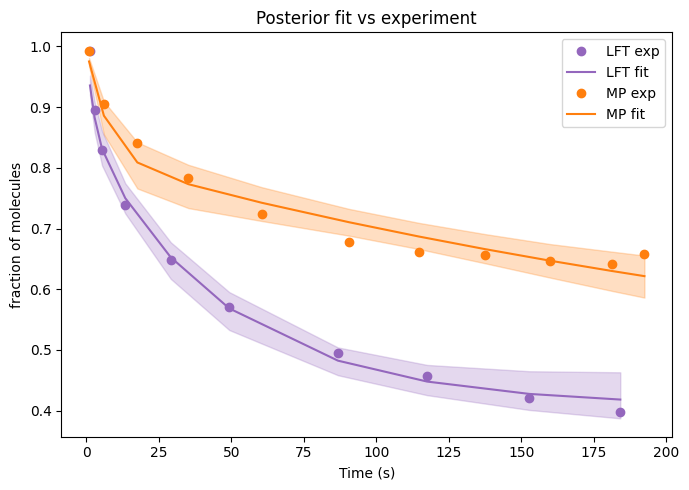

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
lig_names = ["LFT", "MP"]  # adjust if needed
colors = ["C4", "C1"]     # one color per ligand

def flat(var):
    x = idata.posterior[var].values  # (chain, draw, N_total_points)
    return x.reshape(-1, x.shape[-1])

yhat_s = flat("y_hat")
yhat_mean = yhat_s.mean(axis=0)
yhat_lo   = np.quantile(yhat_s, 0.025, axis=0)
yhat_hi   = np.quantile(yhat_s, 0.975, axis=0)
fig, ax = plt.subplots(figsize=(7,5))

start = 0
for ell in range(L):
    end = start + n_per[ell]
    t_ell = t_all[start:end]
    y_ell = y_all[start:end]
    m_ell = yhat_mean[start:end]
    lo_ell = yhat_lo[start:end]
    hi_ell = yhat_hi[start:end]
    c = colors[ell]

    ax.plot(t_ell, y_ell, 'o', color=c, label=f"{lig_names[ell]} exp")
    ax.plot(t_ell, m_ell, '-', color=c, label=f"{lig_names[ell]} fit")
    ax.fill_between(t_ell, lo_ell, hi_ell, color=c, alpha=0.25)
    start = end

ax.set_xlabel("Time (s)")
ax.set_ylabel("fraction of molecules")
ax.set_title("Posterior fit vs experiment")
ax.legend()
plt.tight_layout()
plt.show()


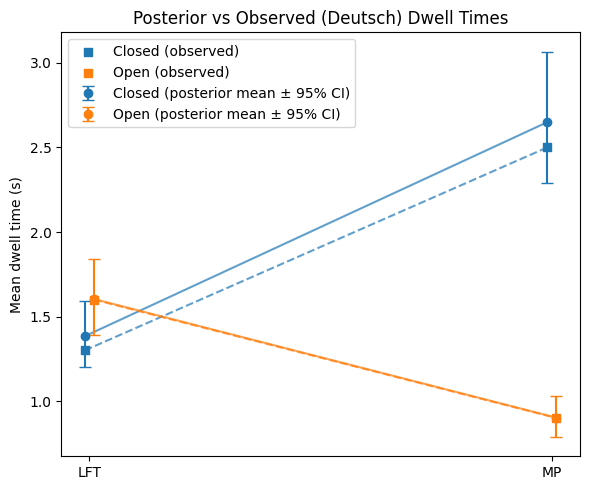

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

tau_co_obs = np.array([1.3, 2.5], dtype=float)
tau_oc_obs = np.array([1.6, 0.9], dtype=float)

lig_names = ["LFT", "MP"]
L = len(tau_co_obs)

def flat(var):
    x = idata.posterior[var].values  # (chain, draw, L)
    return x.reshape(-1, x.shape[-1])

def summary(x):
    mean = x.mean(axis=0)
    lo = np.quantile(x, 0.025, axis=0)
    hi = np.quantile(x, 0.975, axis=0)
    return mean, lo, hi

tau_co_post = flat("tau_co")
tau_oc_post = flat("tau_oc")

co_mean, co_lo, co_hi = summary(tau_co_post)
oc_mean, oc_lo, oc_hi = summary(tau_oc_post)

x = np.arange(L)
offset = 0.01

x_co = x - offset
x_oc = x + offset

fig, ax = plt.subplots(figsize=(6, 5))

# ---- CONNECTING LINES (same color) ----
# Posterior means: solid line
ax.plot(x_co, co_mean, '-', color='C0', alpha=0.7)
ax.plot(x_oc, oc_mean, '-', color='C1', alpha=0.7)

# Observations: dashed line
ax.plot(x_co, tau_co_obs, '--', color='C0', alpha=0.7)
ax.plot(x_oc, tau_oc_obs, '--', color='C1', alpha=0.7)

# ---- POINTS + ERRORBARS ----
# Closed (blue)
ax.errorbar(x_co, co_mean, yerr=[co_mean - co_lo, co_hi - co_mean], fmt='o', color='C0', capsize=4, label="Closed (posterior mean ± 95% CI)")
ax.scatter(x_co, tau_co_obs, marker='s', color='C0', label="Closed (observed)")

# Open (red)
ax.errorbar( x_oc, oc_mean, yerr=[oc_mean - oc_lo, oc_hi - oc_mean], fmt='o', color='C1', capsize=4, label="Open (posterior mean ± 95% CI)")
ax.scatter(x_oc, tau_oc_obs, marker='s', color='C1', label="Open (observed)")

ax.set_xticks(x)
ax.set_xticklabels(lig_names)
ax.set_ylabel("Mean dwell time (s)")
ax.set_title("Posterior vs Observed (Deutsch) Dwell Times")
ax.legend(loc="best")
plt.tight_layout()
plt.show()


In [ ]:
import arviz as az
summ = az.summary(idata,var_names=["tau1","tau2","fN","z_f"])
#summ = add_KL_to_summary(summ, trace, prior_info)
summ

,mean,sd,hdi_3%,hdi_97%,mcse_mean,mcse_sd,ess_bulk,ess_tail,r_hat
tau1[0],2.685,0.218,2.299,3.091,0.003,0.004,4273.0,2723.0,1.0
tau1[1],7.079,0.626,5.991,8.282,0.009,0.011,5112.0,2856.0,1.0
tau2[0],48.283,9.520,30.699,67.129,0.253,0.284,1490.0,945.0,1.0
tau2[1],342.135,67.575,223.814,481.838,1.794,1.990,1495.0,973.0,1.0
fN[0],0.047,0.000,0.047,0.048,0.000,0.000,5339.0,3292.0,1.0
fN[1],0.007,0.000,0.007,0.007,0.000,0.000,4741.0,2995.0,1.0
z_f[0],-3.000,0.010,-3.018,-2.982,0.000,0.000,5339.0,3292.0,1.0
z_f[1],-5.000,0.010,-5.019,-4.982,0.000,0.000,4741.0,2995.0,1.0
